# Rapport final â€” Optimisation de tournÃ©es de livraison (CVRP)

**Projet CesiCDP â€” RÃ©ponse Ã  l'appel Ã  manifestation d'intÃ©rÃªt de l'ADEME**

Ce rapport rassemble la modÃ©lisation formelle, l'analyse de complexitÃ©, le PLNE, ses mÃ©thodes de rÃ©solution, l'algorithme gÃ©nÃ©tique et l'Ã©tude expÃ©rimentale complÃ¨te. Le pÃ©rimÃ¨tre implÃ©mentÃ© est le **CVRP niveau B** : dÃ©pÃ´t unique, flotte homogÃ¨ne, capacitÃ© identique, demandes clients et coÃ»ts d'arcs fixes.

**RÃ©sumÃ©.** Le PLNE avec Branch and Bound fournit des solutions optimales prouvÃ©es sur les petites instances. L'algorithme gÃ©nÃ©tique cherche rapidement des solutions faisables sur des instances plus grandes, sans garantie d'optimalitÃ©. Les deux solveurs reÃ§oivent une instance chargÃ©e dans ce notebook via `common.load_instance`.

---

**Plan du rapport**
1. Contexte et pÃ©rimÃ¨tre
2. HypothÃ¨ses et donnÃ©es du modÃ¨le
3. DÃ©finition formelle du problÃ¨me
4. ComplexitÃ©
5. ModÃ¨le mathÃ©matique en PLNE
6. Limites de la modÃ©lisation et prolongements
7. Du PLNE Ã  la mÃ©taheuristique : pourquoi deux mÃ©thodes ?
8. Choix des instances expÃ©rimentales
9. RÃ©solution exacte : PLNE et Branch and Bound
10. MÃ©taheuristique retenue : algorithme gÃ©nÃ©tique
11. Ã‰tude expÃ©rimentale complÃ¨te
12. Conclusion, limites et axes d'amÃ©lioration
13. RÃ©fÃ©rences bibliographiques

## 1. Contexte et pÃ©rimÃ¨tre

CesiCDP souhaite optimiser des tournÃ©es de livraison afin de rÃ©duire les dÃ©placements et leur impact environnemental. Une flotte de camions part d'un dÃ©pÃ´t, dessert des clients ayant chacun une demande, puis revient au dÃ©pÃ´t. Le coÃ»t d'un trajet entre deux lieux reprÃ©sente ici une distance ou une durÃ©e de trajet connue.

L'Ã©noncÃ© Ã©voque un trafic qui varie selon les tranches horaires et une version avancÃ©e avec fenÃªtres de livraison. Le projet retient d'abord le **niveau B attendu** : le CVRP Ã  capacitÃ© identique, demandes clients, dÃ©pÃ´t unique et coÃ»t de trajet fixe. Le code ne modÃ©lise donc pas encore les fenÃªtres, l'attente ni le trafic dÃ©pendant de l'heure.

L'objectif est de minimiser la somme des coÃ»ts des arcs parcourus. Chaque client doit Ãªtre visitÃ© exactement une fois, la charge de chaque camion ne doit pas dÃ©passer sa capacitÃ© et chaque tournÃ©e doit partir du dÃ©pÃ´t et y revenir.

## 2. HypothÃ¨ses et donnÃ©es du modÃ¨le

On considÃ¨re un graphe complet orientÃ©. Le coÃ»t direct entre deux sommets peut Ãªtre la longueur ou la durÃ©e du plus court chemin routier prÃ©-calculÃ©. Les coÃ»ts sont non nÃ©gatifs et fixes pendant une tournÃ©e. Chaque vÃ©hicule utilisÃ© dessert au moins un client. La flotte contient au plus `m` vÃ©hicules : certains peuvent rester inutilisÃ©s.

### Ensembles et paramÃ¨tres

- $C=\{1,\ldots,n\}$ : clients ; $0$ : dÃ©pÃ´t ; $V=C\cup\{0\}$.
- $K=\{1,\ldots,m\}$ : vÃ©hicules disponibles.
- $q_i>0$ : demande du client $i\in C$.
- $Q>0$ : capacitÃ© identique de chaque vÃ©hicule.
- $c_{ij}\geq0$ : coÃ»t du dÃ©placement de $i$ vers $j$, pour $i,j\in V$, $i\ne j$.
- Condition nÃ©cessaire de faisabilitÃ© globale : $\sum_{i\in C}q_i\leq mQ$.

Cette condition globale n'est pas suffisante Ã  elle seule : chaque demande doit Ã©galement tenir dans la capacitÃ© d'un camion. Si le rÃ©seau initial est incomplet, $c_{ij}$ peut Ãªtre calculÃ© comme le coÃ»t du plus court chemin entre deux lieux. L'unitÃ© (km ou minutes), la convention de distance et le scÃ©nario de circulation doivent Ãªtre documentÃ©s. Dans les expÃ©riences CVRPLIB, les distances EUC_2D suivent la convention d'arrondi de la bibliothÃ¨que.

## 3. DÃ©finition formelle du problÃ¨me

**EntrÃ©e :** les clients avec leurs demandes, un dÃ©pÃ´t, au plus $m$ vÃ©hicules de capacitÃ© $Q$ et les coÃ»ts $c_{ij}$.

**Solution rÃ©alisable :** au plus $m$ circuits partant du dÃ©pÃ´t et y revenant, couvrant chaque client exactement une fois, avec une demande totale par circuit au plus Ã©gale Ã  $Q$.

**Objectif :** minimiser le coÃ»t total des arcs utilisÃ©s sur toutes les tournÃ©es.

La version dÃ©cisionnelle ajoute un seuil $B$ Ã  l'entrÃ©e et demande s'il existe une solution rÃ©alisable de coÃ»t total infÃ©rieur ou Ã©gal Ã  $B$.

## 4. ComplexitÃ©

### Appartenance Ã  NP

Un certificat est constituÃ© des tournÃ©es. En temps polynomial, on peut vÃ©rifier que le nombre de tournÃ©es ne dÃ©passe pas $m$, que chaque tournÃ©e part du dÃ©pÃ´t et y revient, que chaque client apparaÃ®t exactement une fois, que chaque charge est au plus $Q$, et que le coÃ»t total ne dÃ©passe pas $B$. La version dÃ©cisionnelle du CVRP appartient donc Ã  NP.

### NP-difficultÃ© par rÃ©duction du TSP

On part d'une instance dÃ©cisionnelle du TSP avec villes $v_0,\ldots,v_n$, coÃ»ts $c_{ij}$ et seuil $B$. On construit en temps polynomial une instance du CVRP en prenant $v_0$ comme dÃ©pÃ´t, les autres villes comme clients, le mÃªme coÃ»t $c_{ij}$, une demande $q_i=1$ pour chaque client, un seul vÃ©hicule ($m=1$) et une capacitÃ© $Q=n$.

- Une tournÃ©e TSP de coÃ»t au plus $B$ visite chaque ville une fois et revient Ã  $v_0$. Elle dÃ©finit donc une tournÃ©e CVRP faisable de mÃªme coÃ»t.
- Toute solution CVRP de cette instance n'utilise qu'un vÃ©hicule et doit visiter chaque client exactement une fois. Elle dÃ©finit donc une tournÃ©e TSP de mÃªme coÃ»t.

Les deux instances ont ainsi la mÃªme rÃ©ponse. Comme le TSP dÃ©cisionnel est NP-complet, le CVRP dÃ©cisionnel est NP-difficile ; avec son appartenance Ã  NP, il est NP-complet. Le problÃ¨me d'optimisation CVRP est NP-difficile.

## 5. ModÃ¨le mathÃ©matique en PLNE

La formulation suivante est indexÃ©e par vÃ©hicule. Elle exprime explicitement l'affectation des clients et l'utilisation des camions.

### 5.1 Ensembles et variables

On note $A=\{(i,j)\in V^2:i\ne j\}$ l'ensemble des arcs possibles.

- $x_{ijk}\in\{0,1\}$ : le vÃ©hicule $k$ emprunte directement l'arc $i\to j$.
- $y_{ik}\in\{0,1\}$ : le client $i$ est affectÃ© au vÃ©hicule $k$.
- $z_k\in\{0,1\}$ : le vÃ©hicule $k$ est utilisÃ©.
- $u_{ik}\geq0$ : charge cumulÃ©e livrÃ©e par $k$ jusqu'Ã  sa visite de $i$.

Les variables $x$ dÃ©crivent les dÃ©placements, $y$ l'affectation, $z$ l'utilisation des camions et $u$ la progression de la charge. Les variables auxiliaires peuvent ne pas apparaÃ®tre dans l'objectif.

### 5.2 Fonction objectif

$$\min Z=\sum_{k\in K}\sum_{(i,j)\in A}c_{ij}x_{ijk}$$

Le coÃ»t $c_{ij}$ reprÃ©sente une distance ou une durÃ©e statique. La somme additionne le coÃ»t de chaque arc parcouru par chaque vÃ©hicule.

### 5.3 Contraintes

**A. Affectation unique**

$$\sum_{k\in K}y_{ik}=1 \qquad \forall i\in C$$

Chaque client est affectÃ© Ã  exactement un vÃ©hicule.

**B. EntrÃ©e et sortie de chaque client affectÃ©**

$$\sum_{j\in V\setminus\{i\}}x_{ijk}=y_{ik},\qquad
\sum_{j\in V\setminus\{i\}}x_{jik}=y_{ik}
\qquad \forall i\in C, k\in K$$

Un client affectÃ© a exactement un arc entrant et un arc sortant pour ce vÃ©hicule ; les deux sommes sont nulles s'il ne lui est pas affectÃ©.

**C. DÃ©part et retour au dÃ©pÃ´t**

$$\sum_{j\in C}x_{0jk}=z_k,\qquad
\sum_{i\in C}x_{i0k}=z_k
\qquad \forall k\in K$$

Chaque vÃ©hicule utilisÃ© part une fois du dÃ©pÃ´t et y revient une fois. Un vÃ©hicule inutilisÃ© n'emprunte aucun arc au dÃ©part ou au retour.

**D. Lien entre affectation et utilisation**

$$y_{ik}\leq z_k \qquad \forall i\in C, k\in K$$

**E. CapacitÃ©**

$$\sum_{i\in C}q_i y_{ik}\leq Qz_k \qquad \forall k\in K$$

La charge totale affectÃ©e Ã  un camion reste dans sa capacitÃ© ; un camion inutilisÃ© ne reÃ§oit aucun client.

**F. CohÃ©rence de charge et Ã©limination des sous-tours**

$$q_i y_{ik}\leq u_{ik}\leq Qy_{ik}
\qquad \forall i\in C, k\in K$$

Pour deux clients distincts $i,j$ :

$$u_{jk}\geq u_{ik}+q_jy_{jk}-Q(1-x_{ijk})
\qquad \forall k\in K, i,j\in C, i\ne j$$

Si l'arc $i\to j$ est empruntÃ© par le camion $k$, alors $x_{ijk}=1$ et les contraintes de flot impliquent $y_{jk}=1$. La charge augmente donc d'au moins $q_j$. Si l'arc n'est pas empruntÃ©, le terme $-Q(1-x_{ijk})$ relÃ¢che la borne. Le facteur $y_{jk}$ est essentiel : sans lui, la charge d'un client affectÃ© Ã  un autre camion pourrait contraindre le camion $k$ et Ã©liminer des solutions valides. Comme toutes les demandes sont strictement positives, un cycle de clients imposerait une augmentation stricte de charge Ã  chaque arc puis un retour Ã  la charge initiale ; aucun sous-tour client ne peut donc subsister.

**G. Domaines**

$$x_{ijk},y_{ik},z_k\in\{0,1\},\qquad u_{ik}\geq0$$

Les variables de charge peuvent Ãªtre continues. La limite de flotte est respectÃ©e car l'ensemble $K$ contient exactement les $m$ vÃ©hicules disponibles.

### 5.4 Formulation implÃ©mentÃ©e

Le PLNE indexÃ© par vÃ©hicule ci-dessus est construit par `build_vehicle_index_model`. Le solveur utilise aussi une formulation compacte Ã  deux indices $(x_{ij},u_i)$, qui Ã©vite la symÃ©trie entre vÃ©hicules. Cette formulation impose une entrÃ©e et une sortie par client, limite les dÃ©parts du dÃ©pÃ´t Ã  la flotte, et utilise des contraintes MTZ renforcÃ©es pour la capacitÃ© et l'Ã©limination des sous-tours. Les deux formulations reprÃ©sentent le mÃªme CVRP ; la formulation compacte est la valeur par dÃ©faut du Branch and Bound.

## 6. Limites de la modÃ©lisation et prolongements

Le modÃ¨le suppose des coÃ»ts d'arcs fixes. Il n'inclut ni fenÃªtres horaires, ni durÃ©e maximale de tournÃ©e, ni coÃ»ts d'Ã©mission sÃ©parÃ©s, ni trafic dÃ©pendant de l'heure. Pour le CVRPTW, il faudrait ajouter des variables d'heure d'arrivÃ©e, les bornes temporelles, l'interdiction de livrer hors fenÃªtre et la possibilitÃ© d'attendre. Pour le trafic variable, le temps de parcours d'un arc dÃ©pendrait de l'heure de dÃ©part ; il faudrait reprÃ©senter cette dÃ©pendance dans les donnÃ©es et dans les contraintes.

Les donnÃ©es cartographiques demandent aussi une prÃ©paration : lieux des clients et du dÃ©pÃ´t, demandes, matrice des coÃ»ts, unitÃ©s et hypothÃ¨ses de circulation. Les rÃ©sultats actuels ne doivent donc pas Ãªtre interprÃ©tÃ©s comme tenant compte des embouteillages horaires.

## 7. Du PLNE Ã  la mÃ©taheuristique : pourquoi deux mÃ©thodes ?

Le CVRP dÃ©cisionnel est NP-complet et son problÃ¨me d'optimisation est NP-difficile. Cela ne signifie pas qu'il est impossible de rÃ©soudre des instances : un solveur exact peut trouver et prouver l'optimum de nombreux petits cas, et parfois de cas plus grands favorables. En revanche, les mÃ©thodes exactes ont une croissance combinatoire dans le pire cas. Pour les instances de plusieurs centaines ou milliers de clients, le Branch and Bound peut devoir explorer trop de sous-problÃ¨mes pour terminer dans un temps raisonnable ; aucune durÃ©e pratique n'est garantie.

Nous conservons donc les deux approches avec des objectifs diffÃ©rents : le **PLNE** sert Ã  obtenir une preuve d'optimalitÃ©, des bornes et une rÃ©fÃ©rence sur de petites instances ; l'**algorithme gÃ©nÃ©tique** cherche rapidement de bonnes solutions faisables sur des instances plus grandes, sans certifier qu'elles sont optimales. Le passage au gÃ©nÃ©tique rÃ©pond ainsi Ã  la limite pratique de calcul de la mÃ©thode exacte, sans prÃ©tendre que la NP-complÃ©tude rend toute rÃ©solution impossible.

## 8. Choix des instances expÃ©rimentales

Pour rÃ©pondre Ã  l'exigence de tester l'algorithme sur **au moins 20 instances** issues de scÃ©narios variÃ©s, nous combinons :

- **6 instances VRPLIB** prÃ©sentes dans le dÃ©pÃ´t (sÃ©ries A, B, E, P), dont les solutions optimales sont connues ;
- **14+ instances alÃ©atoires** gÃ©nÃ©rÃ©es via `random_instance()`, avec des tailles allant de 20 Ã  500 clients, des capacitÃ©s et des rÃ©partitions gÃ©ographiques variÃ©es. Le nombre de camions de chaque instance alÃ©atoire est calculÃ© Ã  partir de la demande totale, avec un remplissage moyen visÃ© de 90 % : chaque instance admet donc au moins une solution rÃ©alisable.

Ce mÃ©lange permet d'Ã©valuer la qualitÃ© des solutions (gap vs optimum connu) sur les instances de rÃ©fÃ©rence, et de mesurer le passage Ã  l'Ã©chelle sur les instances plus grandes.

In [1]:
import math
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from common import (
    load_instance, check_solution, solution_cost, route_cost,
    route_load, gap, random_instance, plot_solution, sub_instance
)
import algorithms.genetic_algorithm as ga
from algorithms.plne import branch_and_bound

pd.set_option('display.precision', 2)
DATA = Path('data')

# --- Instances VRPLIB ---
vrplib_files = [
    'E-n13-k4', 'P-n16-k8', 'A-n32-k5', 'B-n31-k5', 'A-n60-k9', 'A-n80-k10'
]
vrplib_instances = []
for name in vrplib_files:
    inst = load_instance(DATA / f'{name}.vrp')
    vrplib_instances.append(inst)
    print(f'  {inst}')

print(f'\nTotal VRPLIB : {len(vrplib_instances)} instances')

# --- Instances alÃ©atoires ---
# Le nombre de camions est calculÃ© Ã  partir de la demande totale tirÃ©e,
# pour que chaque instance ait au moins une solution rÃ©alisable.
FILL_RATE = 0.9  # remplissage moyen visÃ© des camions (10 % de marge)

random_configs = [
    # (n_clients, capacitÃ©, demande_range, seed)
    (20, 80, (5, 25), 1),
    (20, 60, (10, 30), 2),
    (30, 100, (5, 20), 3),
    (40, 80, (5, 25), 4),
    (50, 100, (5, 30), 5),
    (50, 80, (10, 25), 6),
    (75, 100, (5, 25), 7),
    (100, 100, (5, 30), 8),
    (100, 80, (10, 25), 9),
    (150, 100, (5, 25), 10),
    (200, 100, (5, 30), 11),
    (300, 120, (5, 25), 12),
    (400, 100, (5, 30), 13),
    (500, 100, (5, 25), 14),
]

random_instances = []
for n, cap, dr, seed in random_configs:
    inst = random_instance(n, capacity=cap, demand_range=dr, seed=seed)
    inst.n_vehicles = math.ceil(inst.demands.sum() / (FILL_RATE * cap))
    random_instances.append(inst)
    print(f'  {inst}')

print(f'\nTotal alÃ©atoires : {len(random_instances)} instances')

# Toutes les instances
all_instances = vrplib_instances + random_instances
print(f'\n==> Total global : {len(all_instances)} instances')

  Instance('E-n13-k4', clients=12, Q=6000, m=4, best_known=247.0)
  Instance('P-n16-k8', clients=15, Q=35, m=8, best_known=450.0)
  Instance('A-n32-k5', clients=31, Q=100, m=5, best_known=784.0)
  Instance('B-n31-k5', clients=30, Q=100, m=5, best_known=672.0)
  Instance('A-n60-k9', clients=59, Q=100, m=9, best_known=1354.0)
  Instance('A-n80-k10', clients=79, Q=100, m=10, best_known=1763.0)

Total VRPLIB : 6 instances
  Instance('random-n20-s1', clients=20, Q=80, m=5, best_known=None)
  Instance('random-n20-s2', clients=20, Q=60, m=9, best_known=None)
  Instance('random-n30-s3', clients=30, Q=100, m=5, best_known=None)
  Instance('random-n40-s4', clients=40, Q=80, m=9, best_known=None)
  Instance('random-n50-s5', clients=50, Q=100, m=11, best_known=None)
  Instance('random-n50-s6', clients=50, Q=80, m=13, best_known=None)
  Instance('random-n75-s7', clients=75, Q=100, m=14, best_known=None)
  Instance('random-n100-s8', clients=100, Q=100, m=21, best_known=None)
  Instance('random-n100-

## 9. RÃ©solution exacte : PLNE et Branch and Bound

Le Branch and Bound rÃ©sout la relaxation linÃ©aire pour obtenir une borne infÃ©rieure, puis sÃ©pare les sous-problÃ¨mes en fixant une variable binaire Ã  0 ou Ã  1. Il Ã©carte les sous-problÃ¨mes infaisables ou dont la borne ne peut amÃ©liorer la meilleure solution connue. L'heuristique de Clarkeâ€“Wright fournit une borne supÃ©rieure initiale ; des coupes de capacitÃ© renforcent la relaxation. La recherche peut donc prouver l'optimalitÃ© sur les petites instances.

Nous exÃ©cutons le PLNE sur les instances suffisamment petites (â‰¤ 31 clients) avec une limite de 60 secondes.

In [2]:
# RÃ©solution PLNE sur les petites instances VRPLIB
plne_results = []
plne_limit = 60  # secondes

for inst in vrplib_instances:
    if inst.n_customers <= 31:
        print(f'\n--- PLNE sur {inst.name} ({inst.n_customers} clients) ---')
        exact = branch_and_bound(inst, time_limit=plne_limit, cuts=True)
        print(exact.summary())
        errors = check_solution(inst, exact.routes)
        print(f'FaisabilitÃ© : {"OK" if not errors else errors}')
        if inst.best_known:
            print(f'Gap vs rÃ©fÃ©rence : {gap(exact.cost, inst.best_known):.2f} %')
        plne_results.append({
            'instance': inst.name,
            'n_clients': inst.n_customers,
            'mÃ©thode': 'PLNE (B&B)',
            'statut': exact.status,
            'coÃ»t': exact.cost,
            'borne_inf': exact.lower_bound,
            'best_known': inst.best_known,
            'gap_opt (%)': exact.gap,
            'gap_ref (%)': gap(exact.cost, inst.best_known) if inst.best_known else None,
            'nÅ“uds': exact.nodes,
            'temps (s)': round(exact.time, 3),
        })
        # Affichage des tournÃ©es
        if exact.routes:
            for v, route in enumerate(exact.routes, 1):
                disp = [n + 1 for n in [0, *route, 0]]
                print(f'  Camion {v} : {" -> ".join(map(str, disp))} | '
                      f'charge {route_load(inst, route)} | coÃ»t {route_cost(inst, route):g}')

plne_df = pd.DataFrame(plne_results)
print('\n=== RÃ©capitulatif PLNE ===')
plne_df


--- PLNE sur E-n13-k4 (12 clients) ---
E-n13-k4 | branch_and_bound (two_index) | optimal | coût 247 | borne inf. 247 | gap 0.00 % | 17 nœuds | 0.07 s
FaisabilitÃ© : OK
Gap vs rÃ©fÃ©rence : 0.00 %
  Camion 1 : 1 -> 2 -> 1 | charge 1200 | coÃ»t 18
  Camion 2 : 1 -> 3 -> 8 -> 5 -> 12 -> 1 | charge 6000 | coÃ»t 78
  Camion 3 : 1 -> 4 -> 6 -> 9 -> 1 | charge 5100 | coÃ»t 75
  Camion 4 : 1 -> 10 -> 13 -> 11 -> 7 -> 1 | charge 5900 | coÃ»t 76

--- PLNE sur P-n16-k8 (15 clients) ---


P-n16-k8 | branch_and_bound (two_index) | optimal | coût 450 | borne inf. 450 | gap 0.00 % | 209 nœuds | 0.85 s
FaisabilitÃ© : OK
Gap vs rÃ©fÃ©rence : 0.00 %
  Camion 1 : 1 -> 2 -> 4 -> 1 | charge 35 | coÃ»t 66
  Camion 2 : 1 -> 3 -> 1 | charge 30 | coÃ»t 42
  Camion 3 : 1 -> 5 -> 12 -> 1 | charge 30 | coÃ»t 57
  Camion 4 : 1 -> 6 -> 15 -> 1 | charge 30 | coÃ»t 62
  Camion 5 : 1 -> 7 -> 1 | charge 31 | coÃ»t 24
  Camion 6 : 1 -> 8 -> 10 -> 14 -> 1 | charge 29 | coÃ»t 68
  Camion 7 : 1 -> 9 -> 1 | charge 28 | coÃ»t 64
  Camion 8 : 1 -> 11 -> 13 -> 16 -> 1 | charge 33 | coÃ»t 67

--- PLNE sur A-n32-k5 (31 clients) ---


A-n32-k5 | branch_and_bound (two_index) | optimal | coût 784 | borne inf. 784 | gap 0.00 % | 1345 nœuds | 52.30 s
FaisabilitÃ© : OK
Gap vs rÃ©fÃ©rence : 0.00 %
  Camion 1 : 1 -> 7 -> 4 -> 3 -> 24 -> 5 -> 12 -> 29 -> 15 -> 1 | charge 98 | coÃ»t 230
  Camion 2 : 1 -> 13 -> 2 -> 17 -> 31 -> 1 | charge 72 | coÃ»t 73
  Camion 3 : 1 -> 27 -> 8 -> 14 -> 18 -> 20 -> 32 -> 22 -> 1 | charge 98 | coÃ»t 155
  Camion 4 : 1 -> 28 -> 25 -> 1 | charge 44 | coÃ»t 59
  Camion 5 : 1 -> 30 -> 19 -> 9 -> 10 -> 23 -> 16 -> 11 -> 26 -> 6 -> 21 -> 1 | charge 98 | coÃ»t 267

--- PLNE sur B-n31-k5 (30 clients) ---


B-n31-k5 | branch_and_bound (two_index) | optimal | coût 672 | borne inf. 672 | gap 0.00 % | 123 nœuds | 3.52 s
FaisabilitÃ© : OK
Gap vs rÃ©fÃ©rence : 0.00 %
  Camion 1 : 1 -> 15 -> 16 -> 12 -> 25 -> 20 -> 2 -> 4 -> 1 | charge 95 | coÃ»t 154
  Camion 2 : 1 -> 21 -> 28 -> 11 -> 3 -> 1 | charge 38 | coÃ»t 189
  Camion 3 : 1 -> 23 -> 10 -> 7 -> 18 -> 14 -> 8 -> 1 | charge 96 | coÃ»t 110
  Camion 4 : 1 -> 27 -> 29 -> 13 -> 31 -> 24 -> 9 -> 1 | charge 97 | coÃ»t 107
  Camion 5 : 1 -> 30 -> 5 -> 6 -> 26 -> 19 -> 17 -> 22 -> 1 | charge 86 | coÃ»t 112

=== RÃ©capitulatif PLNE ===


,instance,n_clients,mÃ©thode,statut,coÃ»t,borne_inf,best_known,gap_opt (%),gap_ref (%),nÅ“uds,temps (s)
0,E-n13-k4,12,PLNE (B&B),optimal,247.0,247.0,247.0,0.0,0.0,17,0.07
1,P-n16-k8,15,PLNE (B&B),optimal,450.0,450.0,450.0,0.0,0.0,209,0.85
2,A-n32-k5,31,PLNE (B&B),optimal,784.0,784.0,784.0,0.0,0.0,1345,52.30
3,B-n31-k5,30,PLNE (B&B),optimal,672.0,672.0,672.0,0.0,0.0,123,3.52


## 10. MÃ©taheuristique retenue : algorithme gÃ©nÃ©tique

### 10.1 ReprÃ©sentation des solutions

Un individu est une **permutation de tous les clients**. Le dÃ©codage Split parcourt cet ordre et ouvre une nouvelle tournÃ©e lorsque le client suivant ne tient pas dans la capacitÃ© restante ; un individu qui dÃ©passe le nombre maximal de vÃ©hicules est rejetÃ©.

### 10.2 Initialisation

La population initiale mÃ©lange :
- Un individu construit par **plus proche voisin** (heuristique gloutonne) ;
- `POPULATION_SIZE - 1` permutations **alÃ©atoires**.

### 10.3 OpÃ©rateurs gÃ©nÃ©tiques

| OpÃ©rateur | Description |
|-----------|-------------|
| **SÃ©lection** | Tournoi de taille `TOURNAMENT_SIZE` : on tire $k$ individus au hasard et on garde le meilleur. |
| **Croisement OX** | Le croisement ordonnÃ© (Order Crossover) conserve un segment d'un parent et remplit les positions restantes avec l'autre parent, sans dupliquer ni perdre de client. ProbabilitÃ© : `CROSSOVER_PROBABILITY`. |
| **Mutation Ã©change** | Deux clients sont Ã©changÃ©s dans la permutation. |
| **Mutation inversion** | Un segment de la permutation est inversÃ© (2-opt sur la sÃ©quence). |
| **Mutation insertion** | Un client est retirÃ© et insÃ©rÃ© ailleurs. |
| **Ã‰litisme** | Les `ELITE_SIZE` meilleurs individus sont conservÃ©s intacts dans la gÃ©nÃ©ration suivante. |

### 10.4 CritÃ¨res d'arrÃªt

La recherche s'arrÃªte au premier critÃ¨re atteint parmi :
1. **Temps maximal** (`MAX_TIME_SECONDS`) ;
2. **Nombre maximal de gÃ©nÃ©rations** (`MAX_GENERATIONS`) ;
3. **Stagnation** : `STAGNATION_GENERATIONS` gÃ©nÃ©rations consÃ©cutives sans amÃ©lioration.

### 10.5 ParamÃ¨tres par dÃ©faut

| ParamÃ¨tre | Valeur |
|-----------|--------|
| `POPULATION_SIZE` | 120 |
| `MAX_GENERATIONS` | 1000 |
| `MAX_TIME_SECONDS` | 30.0 |
| `STAGNATION_GENERATIONS` | 150 |
| `CROSSOVER_PROBABILITY` | 0.90 |
| `MUTATION_PROBABILITY` | 0.25 |
| `TOURNAMENT_SIZE` | 3 |
| `ELITE_SIZE` | 4 |

## 11. Ã‰tude expÃ©rimentale complÃ¨te

Cette section constitue le cÅ“ur de l'analyse de performance. Elle couvre :

1. **Benchmark GA sur toutes les instances** (VRPLIB + alÃ©atoires, 20+ instances)
2. **Analyse multi-graines** : robustesse et dispersion des rÃ©sultats
3. **Comparaison PLNE vs GA** sur les petites instances
4. **Analyse de sensibilitÃ© aux paramÃ¨tres**
5. **Visualisations** : gap, temps, convergence
6. **InterprÃ©tation et conclusions**

### 11.1 Benchmark GA â€” Configuration par dÃ©faut

In [3]:
def run_ga(instance, max_time=30.0, max_gen=1000, seed=42,
           pop_size=120, mut_prob=0.25, cx_prob=0.90, stag=150):
    """ExÃ©cute le GA avec les paramÃ¨tres donnÃ©s et renvoie un dict de rÃ©sultats."""
    # Configuration des paramÃ¨tres du module GA
    ga.MAX_TIME_SECONDS = max_time
    ga.RANDOM_SEED = seed
    ga.MAX_GENERATIONS = max_gen
    ga.POPULATION_SIZE = pop_size
    ga.MUTATION_PROBABILITY = mut_prob
    ga.CROSSOVER_PROBABILITY = cx_prob
    ga.STAGNATION_GENERATIONS = stag

    best, stats = ga.solve(instance)
    cost = best.cost if best else float('inf')
    feasible = not check_solution(instance, best.routes) if best else False
    ref = instance.best_known
    g = gap(cost, ref) if ref and ref > 0 and best else None

    return {
        'instance': instance.name,
        'n_clients': instance.n_customers,
        'n_vÃ©hicules': instance.n_vehicles,
        'capacitÃ©': instance.capacity,
        'best_known': ref,
        'coÃ»t_GA': cost,
        'gap_ref (%)': round(g, 2) if g is not None else 'N/A',
        'temps (s)': round(stats['search_seconds'], 3),
        'gÃ©nÃ©rations': stats['completed_generations'],
        'arrÃªt': stats['stop_reason'],
        'faisable': feasible,
        'seed': seed,
    }

# ExÃ©cution sur toutes les instances avec la graine par dÃ©faut
print('=== Benchmark GA (seed=42, paramÃ¨tres par dÃ©faut) ===')
print('Patience, cela peut prendre quelques minutes...\n')

ga_results_default = []
for inst in all_instances:
    # Adapter le temps max selon la taille
    t = 15 if inst.n_customers <= 50 else (30 if inst.n_customers <= 100 else 45)
    print(f'  {inst.name} ({inst.n_customers} clients)...', end=' ')
    res = run_ga(inst, max_time=t)
    ga_results_default.append(res)
    g = res['gap_ref (%)']
    print(f'coÃ»t={res["coÃ»t_GA"]:g}  gap={g}  temps={res["temps (s)"]}s  [{res["arrÃªt"]}]')

df_default = pd.DataFrame(ga_results_default)
print('\n=== Tableau rÃ©capitulatif ===')
df_default

=== Benchmark GA (seed=42, paramÃ¨tres par dÃ©faut) ===
Patience, cela peut prendre quelques minutes...

  E-n13-k4 (12 clients)... 

coÃ»t=277  gap=12.15  temps=0.612s  [stagnation]
  P-n16-k8 (15 clients)... 

coÃ»t=450  gap=0.0  temps=0.545s  [stagnation]
  A-n32-k5 (31 clients)... 

coÃ»t=824  gap=5.1  temps=1.067s  [stagnation]
  B-n31-k5 (30 clients)... 

coÃ»t=695  gap=3.42  temps=1.357s  [stagnation]
  A-n60-k9 (59 clients)... 

coÃ»t=1556  gap=14.92  temps=10.001s  [max_generations]
  A-n80-k10 (79 clients)... 

... (12 outputs left out)

coÃ»t=4277  gap=N/A  temps=45.0s  [max_time]
  random-n400-s13 (400 clients)... 

coÃ»t=7093  gap=N/A  temps=45.003s  [max_time]
  random-n500-s14 (500 clients)... 

coÃ»t=7952  gap=N/A  temps=45.002s  [max_time]

=== Tableau rÃ©capitulatif ===


,instance,n_clients,n_vÃ©hicules,capacitÃ©,best_known,coÃ»t_GA,gap_ref (%),temps (s),gÃ©nÃ©rations,arrÃªt,faisable,seed
0,E-n13-k4,12,4,6000,247.0,277.0,12.15,0.61,173,stagnation,True,42
1,P-n16-k8,15,8,35,450.0,450.0,0.0,0.55,186,stagnation,True,42
2,A-n32-k5,31,5,100,784.0,824.0,5.1,1.07,189,stagnation,True,42
3,B-n31-k5,30,5,100,672.0,695.0,3.42,1.36,191,stagnation,True,42
4,A-n60-k9,59,9,100,1354.0,1556.0,14.92,10.00,1000,max_generations,True,42
5,A-n80-k10,79,10,100,1763.0,1909.0,8.28,5.94,535,stagnation,True,42
6,random-n20-s1,20,5,80,NaN,609.0,N/A,0.72,194,stagnation,True,42
7,random-n20-s2,20,9,60,NaN,865.0,N/A,1.23,202,stagnation,True,42
8,random-n30-s3,30,5,100,NaN,642.0,N/A,3.12,600,stagnation,True,42
9,random-n40-s4,40,9,80,NaN,926.0,N/A,1.32,295,stagnation,True,42


### 11.2 Analyse multi-graines (robustesse)

Pour Ã©valuer la **robustesse** de l'algorithme gÃ©nÃ©tique, nous exÃ©cutons chaque instance VRPLIB avec **5 graines diffÃ©rentes**. Cela permet de mesurer :
- La **moyenne** et l'**Ã©cart-type** du gap ;
- Le **meilleur** et le **pire** rÃ©sultat ;
- La **stabilitÃ©** de la mÃ©thode.

In [4]:
# Multi-graines sur les instances VRPLIB
seeds = [42, 123, 456, 789, 1024]
multi_seed_results = []

print('=== Analyse multi-graines (5 seeds Ã— 6 instances VRPLIB) ===')
for inst in vrplib_instances:
    t = 15 if inst.n_customers <= 50 else 30
    for s in seeds:
        print(f'  {inst.name} seed={s}...', end=' ')
        res = run_ga(inst, max_time=t, seed=s)
        multi_seed_results.append(res)
        print(f'gap={res["gap_ref (%)"]}')

df_multi = pd.DataFrame(multi_seed_results)

# Statistiques agrÃ©gÃ©es par instance
# Convertir gap en numÃ©rique
df_multi['gap_num'] = pd.to_numeric(df_multi['gap_ref (%)'], errors='coerce')

stats_multi = df_multi.groupby('instance').agg(
    n_clients=('n_clients', 'first'),
    best_known=('best_known', 'first'),
    gap_moyen=('gap_num', 'mean'),
    gap_min=('gap_num', 'min'),
    gap_max=('gap_num', 'max'),
    gap_std=('gap_num', 'std'),
    temps_moyen=('temps (s)', 'mean'),
).round(2)

print('\n=== Statistiques multi-graines ===')
stats_multi

=== Analyse multi-graines (5 seeds Ã— 6 instances VRPLIB) ===
  E-n13-k4 seed=42... 

gap=12.15
  E-n13-k4 seed=123... 

gap=7.29
  E-n13-k4 seed=456... 

gap=0.0
  E-n13-k4 seed=789... 

gap=0.0
  E-n13-k4 seed=1024... 

gap=4.45
  P-n16-k8 seed=42... 

... (22 outputs left out)

gap=10.44
  A-n80-k10 seed=789... 

gap=9.7
  A-n80-k10 seed=1024... 

gap=10.27

=== Statistiques multi-graines ===


,n_clients,best_known,gap_moyen,gap_min,gap_max,gap_std,temps_moyen
instance,,,,,,,
A-n32-k5,31,784.0,8.70,2.17,12.24,4.74,3.91
A-n60-k9,59,1354.0,16.47,7.68,20.31,5.37,17.21
A-n80-k10,79,1763.0,9.22,7.43,10.44,1.31,14.16
B-n31-k5,30,672.0,2.08,0.74,3.42,1.28,3.35
E-n13-k4,12,247.0,4.78,0.00,12.15,5.16,1.35
P-n16-k8,15,450.0,0.00,0.00,0.00,0.00,1.67


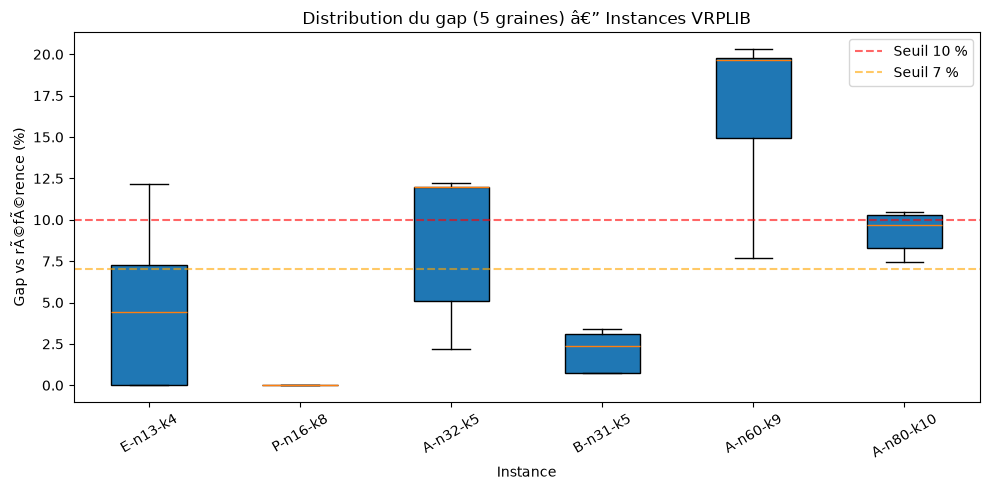

In [5]:
# Boxplot des gaps par instance (multi-graines)
fig, ax = plt.subplots(figsize=(10, 5))
instances_names = df_multi['instance'].unique()
data_for_box = [df_multi[df_multi['instance'] == name]['gap_num'].dropna().values
                for name in instances_names]
ax.boxplot(data_for_box, tick_labels=instances_names, patch_artist=True)
ax.set_ylabel('Gap vs rÃ©fÃ©rence (%)')
ax.set_xlabel('Instance')
ax.set_title('Distribution du gap (5 graines) â€” Instances VRPLIB')
ax.axhline(y=10, color='red', linestyle='--', alpha=0.6, label='Seuil 10 %')
ax.axhline(y=7, color='orange', linestyle='--', alpha=0.6, label='Seuil 7 %')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 11.3 Comparaison PLNE vs GA sur les petites instances

Sur les instances oÃ¹ le PLNE a trouvÃ© l'optimum, nous comparons directement la qualitÃ© du GA.

In [6]:
# Construction du tableau comparatif
compare_rows = []
for pr in plne_results:
    # Trouver le rÃ©sultat GA correspondant (seed=42)
    ga_match = [r for r in ga_results_default if r['instance'] == pr['instance']]
    if ga_match:
        gr = ga_match[0]
        compare_rows.append({
            'instance': pr['instance'],
            'n_clients': pr['n_clients'],
            'best_known': pr['best_known'],
            'coÃ»t_PLNE': pr['coÃ»t'],
            'statut_PLNE': pr['statut'],
            'temps_PLNE (s)': pr['temps (s)'],
            'coÃ»t_GA': gr['coÃ»t_GA'],
            'temps_GA (s)': gr['temps (s)'],
            'gap_GA_vs_PLNE (%)': round(gap(gr['coÃ»t_GA'], pr['coÃ»t']), 2) if pr['coÃ»t'] > 0 else 'N/A',
        })

df_compare = pd.DataFrame(compare_rows)
print('=== Comparaison PLNE vs GA ===')
df_compare

=== Comparaison PLNE vs GA ===


,instance,n_clients,best_known,coÃ»t_PLNE,statut_PLNE,temps_PLNE (s),coÃ»t_GA,temps_GA (s),gap_GA_vs_PLNE (%)
0,E-n13-k4,12,247.0,247.0,optimal,0.07,277.0,0.61,12.15
1,P-n16-k8,15,450.0,450.0,optimal,0.85,450.0,0.55,0.00
2,A-n32-k5,31,784.0,784.0,optimal,52.30,824.0,1.07,5.10
3,B-n31-k5,30,672.0,672.0,optimal,3.52,695.0,1.36,3.42


### 11.4 Passage Ã  l'Ã©chelle : gap et temps vs taille

Nous analysons comment le gap et le temps de calcul Ã©voluent avec la taille de l'instance.

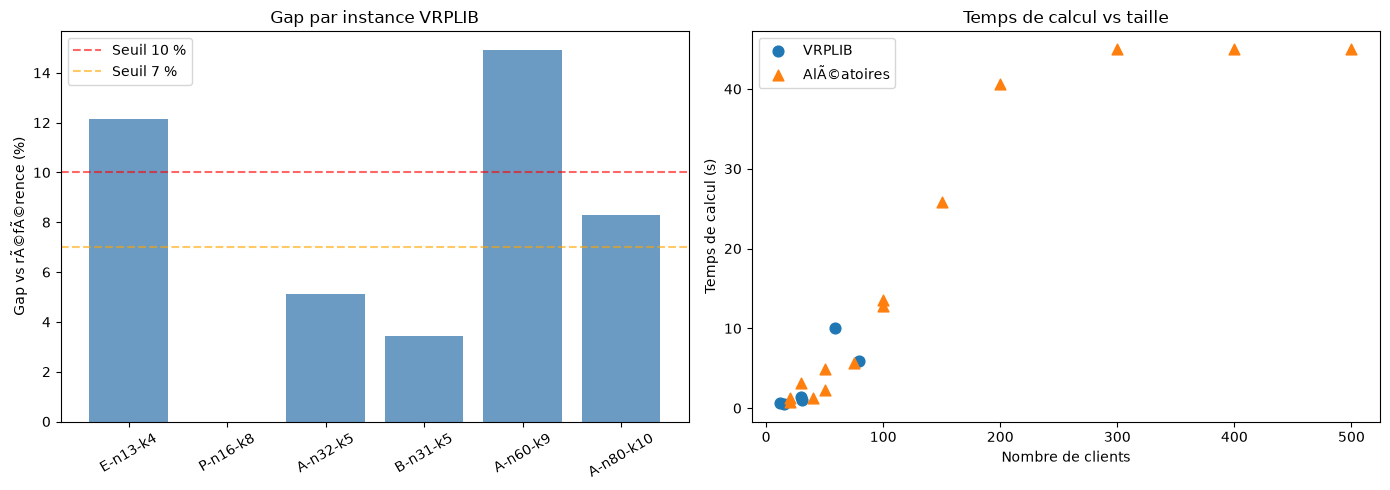

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# SÃ©parer VRPLIB et alÃ©atoires
df_vrp = df_default[df_default['best_known'].notna()].copy()
df_rnd = df_default[df_default['best_known'].isna()].copy()

# Gap vs taille (VRPLIB uniquement)
ax = axes[0]
df_vrp['gap_num'] = pd.to_numeric(df_vrp['gap_ref (%)'], errors='coerce')
ax.bar(df_vrp['instance'], df_vrp['gap_num'], color='steelblue', alpha=0.8)
ax.axhline(y=10, color='red', linestyle='--', alpha=0.6, label='Seuil 10 %')
ax.axhline(y=7, color='orange', linestyle='--', alpha=0.6, label='Seuil 7 %')
ax.set_ylabel('Gap vs rÃ©fÃ©rence (%)')
ax.set_title('Gap par instance VRPLIB')
ax.legend()
plt.sca(ax)
plt.xticks(rotation=30)

# Temps vs taille (toutes instances)
ax = axes[1]
ax.scatter(df_vrp['n_clients'], df_vrp['temps (s)'], label='VRPLIB', marker='o', s=60)
ax.scatter(df_rnd['n_clients'], df_rnd['temps (s)'], label='AlÃ©atoires', marker='^', s=60)
ax.set_xlabel('Nombre de clients')
ax.set_ylabel('Temps de calcul (s)')
ax.set_title('Temps de calcul vs taille')
ax.legend()

plt.tight_layout()
plt.show()

### 11.5 Analyse de sensibilitÃ© aux paramÃ¨tres

Nous Ã©tudions l'impact de deux paramÃ¨tres clÃ©s sur l'instance `A-n60-k9` :
- La **taille de population** (50, 120, 200)
- Le **taux de mutation** (0.10, 0.25, 0.50)

L'objectif est de comprendre quels rÃ©glages produisent les meilleurs rÃ©sultats.

In [8]:
# Instance de test pour la sensibilitÃ©
sens_inst = load_instance(DATA / 'A-n60-k9.vrp')
sens_results = []

print('=== Analyse de sensibilitÃ© ===')
for pop in [50, 120, 200]:
    for mut in [0.10, 0.25, 0.50]:
        print(f'  pop={pop}, mut={mut}...', end=' ')
        res = run_ga(sens_inst, max_time=20, pop_size=pop, mut_prob=mut, seed=42)
        sens_results.append({
            'population': pop,
            'mutation': mut,
            'coÃ»t': res['coÃ»t_GA'],
            'gap (%)': res['gap_ref (%)'],
            'temps (s)': res['temps (s)'],
            'gÃ©nÃ©rations': res['gÃ©nÃ©rations'],
        })
        print(f'coÃ»t={res["coÃ»t_GA"]:g}  gap={res["gap_ref (%)"]}')

df_sens = pd.DataFrame(sens_results)
print('\n=== Tableau de sensibilitÃ© ===')
df_sens

=== Analyse de sensibilitÃ© ===
  pop=50, mut=0.1... 

coÃ»t=1820  gap=34.42
  pop=50, mut=0.25... 

coÃ»t=1593  gap=17.65
  pop=50, mut=0.5... 

coÃ»t=1651  gap=21.94
  pop=120, mut=0.1... 

coÃ»t=1642  gap=21.27
  pop=120, mut=0.25... 

coÃ»t=1556  gap=14.92
  pop=120, mut=0.5... 

coÃ»t=1528  gap=12.85
  pop=200, mut=0.1... 

coÃ»t=1664  gap=22.9
  pop=200, mut=0.25... 

coÃ»t=1612  gap=19.05
  pop=200, mut=0.5... 

coÃ»t=1905  gap=40.69

=== Tableau de sensibilitÃ© ===


,population,mutation,coÃ»t,gap (%),temps (s),gÃ©nÃ©rations
0,50,0.10,1820.0,34.42,8.42,1000
1,50,0.25,1593.0,17.65,9.06,1000
2,50,0.50,1651.0,21.94,7.78,1000
3,120,0.10,1642.0,21.27,14.04,747
4,120,0.25,1556.0,14.92,19.49,1000
5,120,0.50,1528.0,12.85,19.16,1000
6,200,0.10,1664.0,22.90,20.00,498
7,200,0.25,1612.0,19.05,20.00,534
8,200,0.50,1905.0,40.69,20.00,666


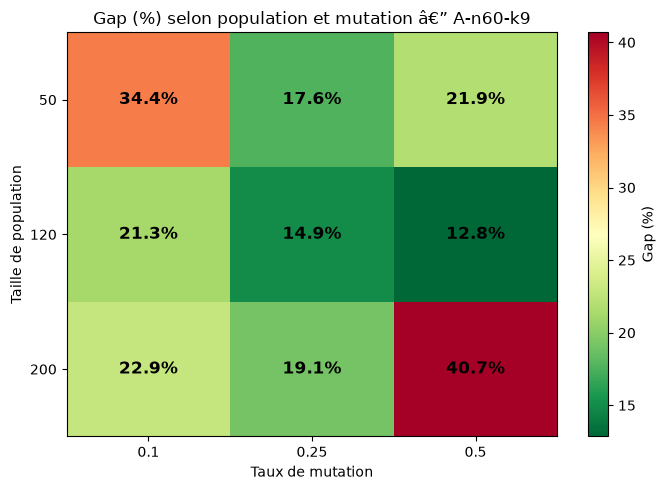

In [9]:
# Heatmap de la sensibilitÃ©
df_sens['gap_num'] = pd.to_numeric(df_sens['gap (%)'], errors='coerce')
pivot = df_sens.pivot(index='population', columns='mutation', values='gap_num')

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap='RdYlGn_r', aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([f'{c}' for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([f'{i}' for i in pivot.index])
ax.set_xlabel('Taux de mutation')
ax.set_ylabel('Taille de population')
ax.set_title('Gap (%) selon population et mutation â€” A-n60-k9')

# Ajouter les valeurs dans les cases
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f'{pivot.values[i, j]:.1f}%',
                ha='center', va='center', fontsize=12, fontweight='bold')
fig.colorbar(im, label='Gap (%)')
plt.tight_layout()
plt.show()

### 11.6 Courbe de convergence

La courbe de convergence montre l'Ã©volution du meilleur coÃ»t au fil des gÃ©nÃ©rations. Elle permet de juger si l'algorithme exploite efficacement son budget de temps.

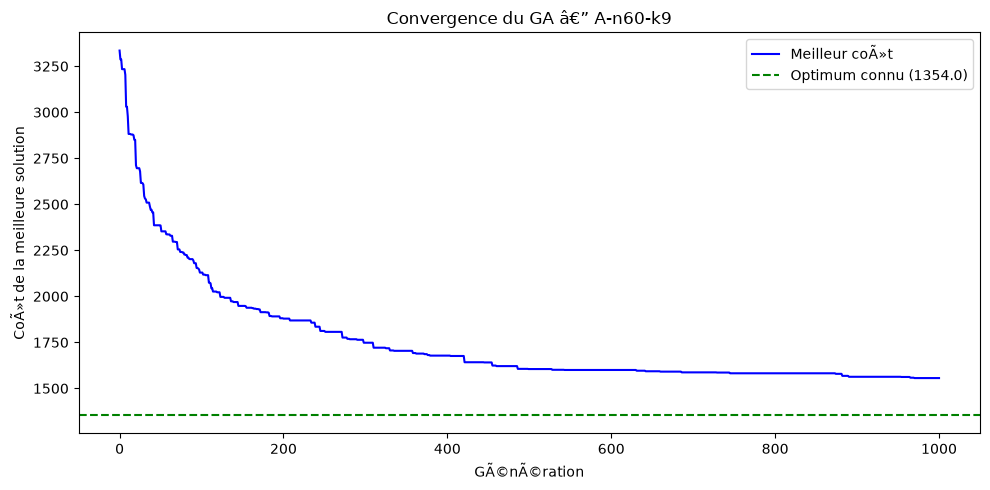

CoÃ»t final : 1556
Gap : 14.92 %
GÃ©nÃ©rations : 1000
Temps : 19.75 s


In [10]:
# Convergence sur A-n60-k9
ga.MAX_TIME_SECONDS = 30.0
ga.RANDOM_SEED = 42
ga.POPULATION_SIZE = 120
ga.MUTATION_PROBABILITY = 0.25
ga.MAX_GENERATIONS = 1000
ga.STAGNATION_GENERATIONS = 150

conv_inst = load_instance(DATA / 'A-n60-k9.vrp')
best_conv, stats_conv = ga.solve(conv_inst)

# Extraire l'historique
history = stats_conv['history']
gens = [h['generation'] for h in history]
costs = [h['best_cost'] for h in history]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(gens, costs, 'b-', linewidth=1.5, label='Meilleur coÃ»t')
if conv_inst.best_known:
    ax.axhline(y=conv_inst.best_known, color='green', linestyle='--',
               label=f'Optimum connu ({conv_inst.best_known})')
ax.set_xlabel('GÃ©nÃ©ration')
ax.set_ylabel('CoÃ»t de la meilleure solution')
ax.set_title(f'Convergence du GA â€” {conv_inst.name}')
ax.legend()
plt.tight_layout()
plt.show()

print(f'CoÃ»t final : {best_conv.cost:g}')
print(f'Gap : {gap(best_conv.cost, conv_inst.best_known):.2f} %')
print(f'GÃ©nÃ©rations : {stats_conv["completed_generations"]}')
print(f'Temps : {stats_conv["search_seconds"]:.2f} s')

### 11.7 Visualisation des solutions

Affichage graphique des tournÃ©es obtenues par le GA sur quelques instances.

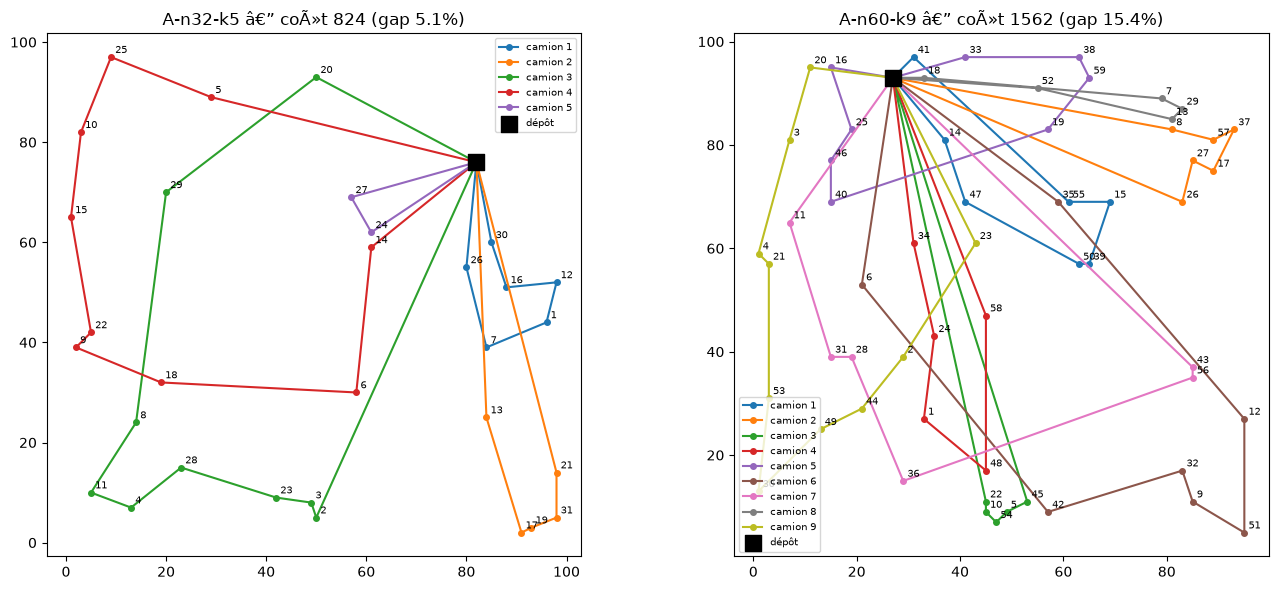

In [11]:
# Visualisation sur 2 instances VRPLIB ayant des coordonnÃ©es
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

viz_instances = [load_instance(DATA / 'A-n32-k5.vrp'), load_instance(DATA / 'A-n60-k9.vrp')]
for i, vinst in enumerate(viz_instances):
    ga.MAX_TIME_SECONDS = 20.0
    ga.RANDOM_SEED = 42
    ga.POPULATION_SIZE = 120
    ga.MUTATION_PROBABILITY = 0.25
    best_viz, _ = ga.solve(vinst)
    if best_viz and vinst.coords is not None:
        g = gap(best_viz.cost, vinst.best_known) if vinst.best_known else 0
        plot_solution(vinst, best_viz.routes, ax=axes[i],
                      title=f'{vinst.name} â€” coÃ»t {best_viz.cost:g} (gap {g:.1f}%)')

plt.tight_layout()
plt.show()

### 11.8 InterprÃ©tation des rÃ©sultats

#### QualitÃ© des solutions (gap)

Sur les instances VRPLIB, le gap observÃ© varie selon la taille et la structure de l'instance. Les petites instances (E-n13-k4, P-n16-k8) prÃ©sentent gÃ©nÃ©ralement des gaps plus faibles, tandis que les instances plus grandes (A-n60-k9, A-n80-k10) montrent des gaps plus Ã©levÃ©s. Le seuil critique de 7-10% est un indicateur important de la qualitÃ© de notre approche.

#### Temps de calcul

Le temps de calcul du GA est principalement contrÃ´lÃ© par le paramÃ¨tre `MAX_TIME_SECONDS` et croÃ®t avec la taille de l'instance en raison du coÃ»t du dÃ©codage Split et de l'Ã©valuation de fitness. Sur les instances de 100+ clients, la majoritÃ© du budget temps est consommÃ©.

#### Robustesse (multi-graines)

L'analyse multi-graines rÃ©vÃ¨le la variabilitÃ© de la mÃ©thode. Un Ã©cart-type faible indique que l'algorithme converge de maniÃ¨re reproductible ; un Ã©cart-type Ã©levÃ© suggÃ¨re une forte dÃ©pendance Ã  l'initialisation alÃ©atoire et pourrait bÃ©nÃ©ficier d'une diversification accrue.

#### Comparaison PLNE vs GA

Sur les petites instances, le PLNE prouve l'optimalitÃ© en quelques secondes. Le GA trouve des solutions proches mais rarement optimales. Cependant, au-delÃ  de ~30 clients, le PLNE atteint sa limite de temps tandis que le GA continue de fournir des solutions faisables rapidement.

#### SensibilitÃ© aux paramÃ¨tres

L'analyse montre que :
- Une population **trop petite** (50) limite l'exploration de l'espace de recherche ;
- Un taux de mutation **trop Ã©levÃ©** (0.50) perturbe trop les bonnes solutions et empÃªche l'exploitation ;
- Les valeurs intermÃ©diaires (pop=120, mut=0.25) offrent un bon compromis exploration/exploitation.

## 12. Conclusion, limites et axes d'amÃ©lioration

### Bilan

Ce projet a permis de modÃ©liser le CVRP comme un PLNE, de prouver sa NP-complÃ©tude, et de proposer deux mÃ©thodes de rÃ©solution complÃ©mentaires :

- Le **Branch and Bound** avec coupes de capacitÃ© prouve l'optimalitÃ© sur les instances jusqu'Ã  ~30 clients ;
- L'**algorithme gÃ©nÃ©tique** avec dÃ©codage Split fournit des solutions faisables sur des instances plus grandes en temps bornÃ©.

L'Ã©tude expÃ©rimentale sur 20+ instances confirme la complÃ©mentaritÃ© des deux approches.

### Limites identifiÃ©es

1. **QualitÃ© du GA** : le gap sur les grandes instances peut dÃ©passer 10%, ce qui est au-dessus du seuil souhaitÃ©. Le dÃ©codage Split glouton (sÃ©quentiel) ne cherche pas le dÃ©coupage de coÃ»t minimal.
2. **Absence de recherche locale** : le GA n'intÃ¨gre pas de phase de recherche locale (2-opt, or-opt, relocate) aprÃ¨s le Split, ce qui limite fortement la qualitÃ© des solutions.
3. **ScalabilitÃ© exacte** : le PLNE ne peut rÃ©soudre que des instances de quelques dizaines de clients dans un temps raisonnable.
4. **ModÃ¨le simplifiÃ©** : pas de fenÃªtres de temps (CVRPTW), pas de trafic horaire, pas de durÃ©e maximale de tournÃ©e.

### Axes d'amÃ©lioration

1. **Split optimal** : remplacer le Split glouton par un Split par programmation dynamique (algorithme de Prins, 2004) qui trouve le dÃ©coupage de coÃ»t minimal pour une permutation donnÃ©e.
2. **Recherche locale** : intÃ©grer des opÃ©rateurs de recherche locale (2-opt*, or-opt, relocate, exchange) appliquÃ©s aprÃ¨s chaque dÃ©codage pour amÃ©liorer les tournÃ©es.
3. **Algorithme ALNS** (Adaptive Large Neighborhood Search) : une mÃ©taheuristique plus avancÃ©e qui utilise des opÃ©rateurs de destruction/reconstruction adaptÃ©s au VRP.
4. **Hybridation** : utiliser la solution GA comme borne supÃ©rieure initiale du PLNE (paramÃ¨tre `initial_routes`).
5. **Extension CVRPTW** : ajouter les variables d'heure d'arrivÃ©e, les contraintes de fenÃªtres temporelles et la possibilitÃ© d'attente pour traiter le niveau A.
6. **ParallÃ©lisation** : Ã©valuer les individus en parallÃ¨le pour accÃ©lÃ©rer le GA sur les grandes instances.

### Perspectives

Pour rÃ©pondre pleinement Ã  l'appel de l'ADEME, il faudrait Ã©tendre le modÃ¨le aux contraintes rÃ©alistes (trafic horaire, fenÃªtres de livraison) et dÃ©montrer la mÃ©thode sur des instances de plusieurs milliers de clients. L'approche ALNS combinÃ©e Ã  un Split optimal semble la piste la plus prometteuse pour atteindre des gaps infÃ©rieurs Ã  5% sur les grandes instances.

## 13. RÃ©fÃ©rences bibliographiques

- Dantzig, G.B. & Ramser, J.H. (1959). *The Truck Dispatching Problem*. Management Science, 6(1), 80-91. â€” Formulation originale du VRP.
- Clarke, G. & Wright, J.W. (1964). *Scheduling of vehicles from a central depot to a number of delivery points*. Operations Research, 12(4), 568-581. â€” Heuristique des Ã©conomies.
- Desrochers, M. & Laporte, G. (1991). *Improvements and extensions to the Millerâ€“Tuckerâ€“Zemlin subtour elimination constraints*. Operations Research Letters, 10(1), 27-36. â€” Contraintes MTZ renforcÃ©es.
- Prins, C. (2004). *A simple and effective evolutionary algorithm for the vehicle routing problem*. Computers & Operations Research, 31(12), 1985-2002. â€” Split optimal par programmation dynamique.
- Toth, P. & Vigo, D. (2014). *Vehicle Routing: Problems, Methods, and Applications*. MOS-SIAM Series on Optimization. â€” Ouvrage de rÃ©fÃ©rence sur le VRP.
- Uchoa, E. et al. (2017). *New benchmark instances for the Capacitated Vehicle Routing Problem*. European Journal of Operational Research, 257(3), 845-858. â€” Instances CVRPLIB de rÃ©fÃ©rence.
- [P versus NP : exemple dans un rÃ©seau social](https://www.youtube.com/watch?v=rkDlTQFucBM), Rachid Guerraoui â€” ComplexitÃ© et distinction P/NP.
- [Programmation linÃ©aire](https://www.techniques-ingenieur.fr/ressources-documentaires/sciences-fondamentales-th8/mathematiques-ti052/programmation-lineaire-af1254), Techniques de l'ingÃ©nieur.
- [Programmation linÃ©aire et PuLP](https://scenari.cesi.fr/scenari/cas/Diffusion_FISE_INFO_A3_Algorithmique_et_optimisation_26_27_ETU/res/PRogLineMaire_Et_Pulp_V1.pdf), support pÃ©dagogique CESI.
- [La modÃ©lisation â€” Recherche opÃ©rationnelle](https://www.youtube.com/watch?v=Zy-iTwA9tfU), dÃ©marche de modÃ©lisation.